# Week 6: Decision Trees and Random Forests
Eric Benaroch, Module C Capstone

Research question from my proposal: does malicious behavior leave the same statistical pattern in different threat domains, or is every domain different?

Same datasets and task as Weeks 4 and 5: predict whether a flow (CICAndMal2017, CICIDS2017) or an article (WELFake) is malicious (1) or benign (0). Random forests are also one of the three model types my proposal plans to use for the SHAP analysis.

Plan:
1. Work through the lesson's examples: entropy, information gain, the interaction case, the apple price tree and the 4-apple overfitting example.
2. Fit decision trees and show overfitting and underfitting with max depth, min samples per leaf and min samples per split.
3. Draw a small tree for each domain and compare the first decisions.
4. Random forests: bagging, feature randomization and how the trees' votes are combined.
5. Feature importances, including the lesson's definition (how often each feature is used for a split).
6. Test the Week 4 and 5 warning that flexible models can memorize CICAndMal2017 capture files.
7. Try all the flow features on CICAndMal2017, and classify whole app captures instead of single flows, to see if either fixes the weak malware results.

## 1. Setup

In [1]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, GridSearchCV, GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import warnings
warnings.filterwarnings("ignore")

import os
from pathlib import Path
DATA_DIR = Path(os.environ.get("CAPSTONE_DATA_DIR", "."))   # folder with the zips and the WELFake csv
FIG_DIR = Path("figures_week6"); FIG_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

## 2. The lesson's examples
### 2a. Entropy and information gain
Entropy of a node = sum of -p ln(p) over the classes. Information gain = entropy of the parent - pA x entropy of A - pB x entropy of B. The lesson's example has 10 good and 10 bad apples at the parent.

In [2]:
def entropy(counts, base=np.e):
    p = np.array(counts) / sum(counts)
    p = p[p > 0]
    return -(p * np.log(p) / np.log(base)).sum()

def info_gain(parent, left, right):
    n = sum(parent)
    return entropy(parent) - sum(left) / n * entropy(left) - sum(right) / n * entropy(right)

print(f"50/50 coin: entropy = {entropy([1, 1]):.4f} (base e), {entropy([1, 1], base=2):.4f} (base 2)")
print(f"10 good / 10 bad apples at the parent: entropy = {entropy([10, 10]):.4f}")
print(f"Perfect split (10 good to A, 10 bad to B): information gain = {info_gain([10, 10], [10, 0], [0, 10]):.4f}")
print(f"Useless split (5 good + 5 bad to each side): information gain = {info_gain([10, 10], [5, 5], [5, 5]):.4f}")

50/50 coin: entropy = 0.6931 (base e), 1.0000 (base 2)
10 good / 10 bad apples at the parent: entropy = 0.6931
Perfect split (10 good to A, 10 bad to B): information gain = 0.6931
Useless split (5 good + 5 bad to each side): information gain = 0.0000


### 2b. When only the interaction matters
The lesson's harder case: good apples are big and heavy or small and light, and bad apples are big and light or small and heavy. Any single split has almost zero information gain, yet the right two splits (diameter > 7 cm, then mass > 80 g) classify every apple correctly. The question is whether a tree, which picks the best split one step at a time, can find them.

In [3]:
rng = np.random.RandomState(0)
diameter = rng.uniform(5, 9, 400); mass = rng.uniform(60, 100, 400)
good = ((diameter > 7) == (mass > 80)).astype(int)
apples = pd.DataFrame({"diameter": diameter, "mass": mass})

for depth in [1, 2, 3, 4, 6]:
    tree = DecisionTreeClassifier(max_depth=depth, criterion="entropy", random_state=SEED).fit(apples, good)
    print(f"tree with depth {depth}: training accuracy = {tree.score(apples, good):.2f}")
hand_rule = ((apples["diameter"] > 7) == (apples["mass"] > 80)).astype(int)
print(f"hand-made tree (diameter > 7, then mass > 80): accuracy = {np.mean(hand_rule == good):.2f}")
print(f"best single split on diameter at 7 cm: information gain = {info_gain([good.sum(), (1 - good).sum()], np.bincount(1 - good[diameter > 7], minlength=2), np.bincount(1 - good[diameter <= 7], minlength=2)):.4f}")

tree with depth 1: training accuracy = 0.51
tree with depth 2: training accuracy = 0.56
tree with depth 3: training accuracy = 0.98
tree with depth 4: training accuracy = 1.00
tree with depth 6: training accuracy = 1.00
hand-made tree (diameter > 7, then mass > 80): accuracy = 1.00
best single split on diameter at 7 cm: information gain = 0.0024


### 2c. The apple price tree (Figure 1 of the lesson)
I make up apples whose price follows the lesson's figure exactly, then let a regression tree learn the rule on its own.

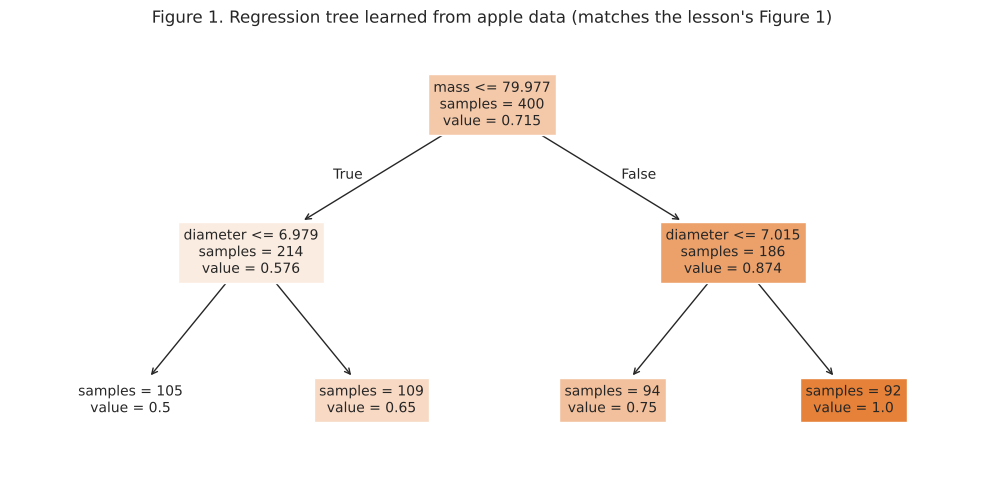

In [4]:
price = np.select([(diameter > 7) & (mass < 80), (diameter > 7) & (mass >= 80), (diameter <= 7) & (mass < 80)], [0.65, 1.00, 0.50], 0.75)
price_tree = DecisionTreeRegressor(max_depth=2).fit(apples, price)
fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(price_tree, feature_names=["diameter", "mass"], filled=True, impurity=False, ax=ax, fontsize=10)
ax.set_title("Figure 1. Regression tree learned from apple data (matches the lesson's Figure 1)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_apple_tree.png", dpi=150); plt.show()

### 2d. The 4-apple overfitting example
Apples with diameters 5 and 8 cm are good, 6 and 7 cm are bad. A full tree fits them perfectly with two cut points (5.5 and 7.5), but this rule is probably just noise.

In [5]:
four = pd.DataFrame({"diameter": [5, 6, 7, 8]}); four_y = [1, 0, 0, 1]
tree4 = DecisionTreeClassifier(criterion="entropy").fit(four, four_y)
print(export_text(tree4, feature_names=["diameter"]))
print("training accuracy:", tree4.score(four, four_y))

|--- diameter <= 5.50
|   |--- class: 1
|--- diameter >  5.50
|   |--- diameter <= 7.50
|   |   |--- class: 0
|   |--- diameter >  7.50
|   |   |--- class: 1

training accuracy: 1.0


Results of the lesson's examples:
- A 50/50 node has entropy 0.693 in base e (ln 2) and exactly 1 in base 2, which is one unknown bit.
- For the 10 good and 10 bad apples, the perfect split has an information gain of 0.693 (all the entropy is removed). The 5-and-5 split gains exactly 0 (nothing is learned).
- In the interaction case, the split at 7 cm only gains 0.0024. Because a tree picks the best split one step at a time, a depth-2 tree does not find the right pair of splits and gets only 56%. With depth 3 it reaches 98%, and with depth 4 it reaches 100%. The hand-made tree with the right two splits gets 100% right away. This is the lesson's point: a split that looks useless on its own can be a necessary step, but a greedy tree may need extra depth to find it.
- The regression tree in Figure 1 recovers the lesson's four prices exactly ($0.50, $0.65, $0.75 and $1.00) with cut points at 7 cm and 80 g. It asks about mass first and diameter second, the reverse of the lesson's figure. Splitting on mass first lowers the error slightly more for this data, and both orders give the same predictions for every apple.
- In the 4-apple example, a full tree draws cut points at 5.5 and 7.5 cm and gets 100% training accuracy, which is almost certainly a coincidence. This is overfitting.

## 3. Load the data
Same data and cleaning as Weeks 4 and 5, keeping the capture file name for CICAndMal2017.

In [6]:
COLS = {"Flow Duration": "dur", "Total Fwd Packets": "fwd_pkts", "Total Backward Packets": "bwd_pkts",
        "Fwd Packet Length Mean": "fwd_len", "Bwd Packet Length Mean": "bwd_len",
        "Flow IAT Mean": "iat", "Flow Bytes/s": "bytes_s", "Label": "label"}

def read_zip(zip_name):
    frames = []
    with zipfile.ZipFile(DATA_DIR / zip_name) as z:
        for name in z.namelist():
            if name.endswith(".csv"):
                df = pd.read_csv(z.open(name), skipinitialspace=True, encoding="latin1",
                                 usecols=lambda c: c.strip() in COLS)
                df.columns = df.columns.str.strip()
                df["file"] = name
                frames.append(df)
    return pd.concat(frames, ignore_index=True).rename(columns=COLS)

mal_parts = []
for cat in ["Benign", "Adware", "Ransomware", "Scareware", "SMSmalware"]:
    df = read_zip(f"{cat}-CSVs.zip")
    df["category"] = cat
    mal_parts.append(df)
    print(cat, len(df), "flows from", df["file"].nunique(), "capture files")
mal_raw = pd.concat(mal_parts, ignore_index=True)

ids_raw = read_zip("MachineLearningCSV.zip")
print("CICIDS2017", len(ids_raw))

Benign 1205515 flows from 1700 capture files


Adware 424147 flows from 104 capture files


Ransomware 348943 flows from 101 capture files


Scareware 400841 flows from 112 capture files


SMSmalware 237133 flows from 109 capture files


CICIDS2017 2830743


In [7]:
wel_raw = pd.read_csv(next(DATA_DIR.glob("WELFake*.csv")))      # finds WELFake_Dataset.csv
print(wel_raw.shape)
print(wel_raw["label"].value_counts())

# Which label is fake? Real news in WELFake is mostly Reuters wire copy.
print(wel_raw.groupby("label")["text"].apply(lambda s: s.str.contains("(Reuters)", regex=False).mean()))

(72134, 4)
label
1    37106
0    35028
Name: count, dtype: int64
label
0   0.607
1   0.000
Name: text, dtype: float64


The dataset card says label 1 means real, but in this file label 0 has the Reuters articles (about 61%) and label 1 has almost none. So label 1 is treated as fake (malicious = 1).

## 4. Clean and prepare
Network data: remove infinite and missing values, negative values, zero-length flows and duplicates, as in Module B. All flow features are very skewed (a few huge flows), so I take log1p of every feature and the target. I take a random sample so the models run quickly: 60,000 flows per CICAndMal2017 category, and 150,000 benign plus 150,000 attack flows for CICIDS2017.

WELFake: drop empty articles and duplicates, then make simple numeric features from the title and text.

In [8]:
def clean_flows(df):
    num = list(COLS.values())[:-1]
    df = df.copy()
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df[num] >= 0).all(axis=1) & (df["dur"] > 0)].drop_duplicates()
    for c in num:
        df[c] = np.log1p(df[c])
    return df.rename(columns={"bytes_s": "y"})

mal = clean_flows(mal_raw)
mal["malicious"] = (mal["category"] != "Benign").astype(int)
mal = mal.groupby("category").sample(60000, random_state=SEED)

def attack_group(label):
    label = label.upper()
    if label == "BENIGN": return "Benign"
    if "DOS" in label: return "DoS/DDoS"
    if "PATATOR" in label: return "BruteForce"
    if "WEB ATTACK" in label: return "WebAttack"
    if "PORTSCAN" in label: return "PortScan"
    return "Other"

ids = clean_flows(ids_raw)
ids["category"] = ids["label"].map(attack_group)
ids["malicious"] = (ids["category"] != "Benign").astype(int)
ids = ids.groupby("malicious").sample(150000, random_state=SEED)

print(mal["category"].value_counts(), "\n")
print(ids["category"].value_counts())

category
Adware        60000
Benign        60000
Ransomware    60000
SMSmalware    60000
Scareware     60000
Name: count, dtype: int64 

category
Benign        150000
DoS/DDoS      144313
BruteForce      3343
WebAttack        982
PortScan         740
Other            622
Name: count, dtype: int64


In [9]:
wel = wel_raw.dropna(subset=["text"]).fillna({"title": ""}).drop_duplicates(subset=["title", "text"])
wel = wel[wel["text"].str.split().str.len() > 0].copy()
wel["malicious"] = wel["label"]                                   # 1 = fake
wel["y"] = np.log1p(wel["text"].str.split().str.len())            # target: log word count
wel["title_words"] = np.log1p(wel["title"].str.split().str.len())
wel["title_chars"] = np.log1p(wel["title"].str.len())
wel["title_caps"] = wel["title"].str.count(r"[A-Z]") / wel["title"].str.len().clip(lower=1)   # share of capital letters
wel["exclaim"] = np.log1p(wel["title"].str.count("!") + wel["text"].str.count("!"))
wel["avg_word_len"] = wel["text"].str.len() / wel["text"].str.split().str.len()
wel["avg_word_len"] = wel["avg_word_len"].clip(upper=wel["avg_word_len"].quantile(0.99))
print(len(wel), "articles, fake share =", round(wel["malicious"].mean(), 2))

63110 articles, fake share = 0.45


## 5. Features for classification
The target is now the malicious label. Throughput (Flow Bytes/s) and word count, which were the targets in Weeks 1 to 3, become features. All features are already on a log scale except title_caps and avg_word_len.

For CICAndMal2017 I split by capture file from now on (whole capture files go to either training or test), because Week 4 found that flows from the same capture are not independent. Section 8 checks how much this matters for trees.

In [10]:
del mal_raw, ids_raw, wel_raw          # free memory, only the cleaned samples are needed
mal = mal.rename(columns={"y": "bytes_s"}).reset_index(drop=True)
ids = ids.rename(columns={"y": "bytes_s"}).reset_index(drop=True)
wel = wel.rename(columns={"y": "word_count"}).reset_index(drop=True)

NET = ["dur", "fwd_pkts", "bwd_pkts", "fwd_len", "bwd_len", "iat", "bytes_s"]
WEL = ["title_words", "title_chars", "title_caps", "exclaim", "avg_word_len", "word_count"]
DATA = {"CICAndMal2017": (mal, NET), "CICIDS2017": (ids, NET), "WELFake": (wel, WEL)}

def split(df, name):
    if name == "CICAndMal2017":
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(df, groups=df["file"]))
        return df.iloc[tr], df.iloc[te]
    return train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["malicious"])

SPLITS = {}
for name, (df, feats) in DATA.items():
    train, test = split(df, name)
    SPLITS[name] = (train[feats], test[feats], train["malicious"].values, test["malicious"].values)
    print(f"{name}: {len(train)} train, {len(test)} test, malicious share in test = {test['malicious'].mean():.2f}")

CICAndMal2017: 238753 train, 61247 test, malicious share in test = 0.80


CICIDS2017: 240000 train, 60000 test, malicious share in test = 0.50
WELFake: 50488 train, 12622 test, malicious share in test = 0.45


## 6. Decision trees: overfitting and underfitting
Trees do not need feature scaling, because each split only compares one feature with a threshold. I use entropy as the split criterion, as in the lesson.

For each dataset I grow trees of depth 1 to 30 and compare training and validation macro F1. The validation set is 20% of the training data (split by capture file for CICAndMal2017).

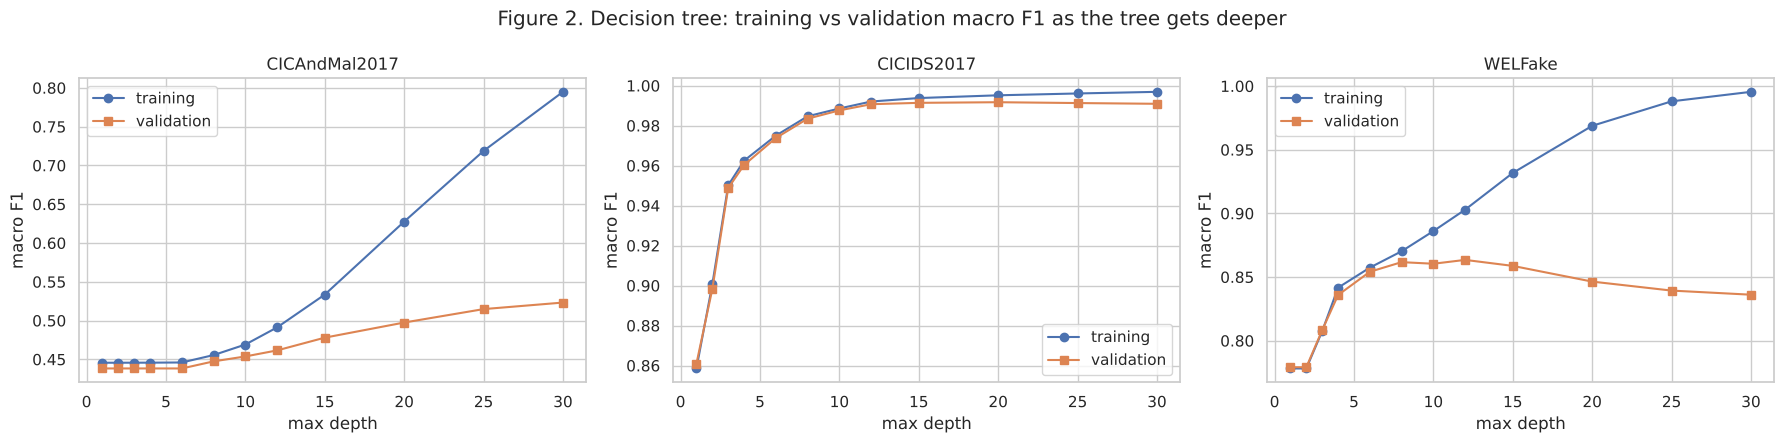

training                       validation                   
dataset   CICAndMal2017 CICIDS2017 WELFake CICAndMal2017 CICIDS2017 WELFake
max depth                                                                  
1                 0.446      0.859   0.778         0.438      0.861   0.779
2                 0.446      0.901   0.778         0.438      0.898   0.779
3                 0.446      0.950   0.808         0.438      0.949   0.808
4                 0.446      0.962   0.842         0.438      0.960   0.836
6                 0.446      0.975   0.857         0.438      0.974   0.854
8                 0.456      0.985   0.870         0.447      0.983   0.862
10                0.469      0.989   0.886         0.454      0.988   0.860
12                0.491      0.992   0.903         0.462      0.991   0.863
15                0.533      0.994   0.932         0.478      0.991   0.859
20                0.628      0.995   0.969         0.497      0.992   0.846
25                0.719      0.996   0.988         0.515      0.991   0.839
30                0.795      0.997   0.995         0.523      0.991   0.836

In [11]:
def val_split(X, y, name, df):
    if name == "CICAndMal2017":
        files = df.loc[X.index, "file"]
        tr, va = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1).split(X, groups=files))
    else:
        tr, va = train_test_split(np.arange(len(X)), test_size=0.2, random_state=1, stratify=y)
    return X.iloc[tr], X.iloc[va], y[tr], y[va]

def macro_f1(model, X, y):
    return f1_score(y, model.predict(X), average="macro")

VAL = {}
depth_rows = []
for name, (Xtr, Xte, ytr, yte) in SPLITS.items():
    VAL[name] = val_split(Xtr, ytr, name, DATA[name][0])
    Xa, Xv, ya, yv = VAL[name]
    for depth in [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, 25, 30]:
        tree = DecisionTreeClassifier(max_depth=depth, criterion="entropy", random_state=SEED).fit(Xa, ya)
        depth_rows.append({"dataset": name, "max depth": depth, "training": macro_f1(tree, Xa, ya),
                           "validation": macro_f1(tree, Xv, yv), "leaves": tree.get_n_leaves()})
depth_df = pd.DataFrame(depth_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, SPLITS):
    d = depth_df[depth_df.dataset == name]
    ax.plot(d["max depth"], d["training"], "o-", label="training")
    ax.plot(d["max depth"], d["validation"], "s-", label="validation")
    ax.set_xlabel("max depth"); ax.set_ylabel("macro F1"); ax.set_title(name); ax.legend()
fig.suptitle("Figure 2. Decision tree: training vs validation macro F1 as the tree gets deeper")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_depth.png", dpi=150); plt.show()
depth_df.pivot(index="max depth", columns="dataset", values=["training", "validation"]).round(3)

Figure 2 shows overfitting and underfitting clearly:
- WELFake: a depth-1 tree underfits (validation macro F1 0.78). Validation peaks around depth 12 (0.863), then falls to 0.836 at depth 30 while training F1 climbs to 0.995. Past that point the tree is learning rules that only fit the training articles, like the lesson's "customers who log in exactly 7 times" example.
- CICIDS2017: attacks are easy to separate, so training and validation stay together and validation levels off around depth 15 (0.991). Going deeper adds leaves but no accuracy.
- CICAndMal2017: up to depth 6 the tree predicts malware for everything (0.438). After that, training F1 rises to 0.795 at depth 30 while validation only creeps to 0.523. Almost all of what the deep tree learns is specific to the training captures.

### 6b. Min samples per leaf and min samples per split
The two other stopping rules from the lesson, applied to a tree with no depth limit.

In [12]:
leaf_rows = []
for name in SPLITS:
    Xa, Xv, ya, yv = VAL[name]
    for n in [1, 5, 20, 100, 500, 2000]:
        for rule in ["min_samples_leaf", "min_samples_split"]:
            value = n if rule == "min_samples_leaf" else max(2, n)
            tree = DecisionTreeClassifier(criterion="entropy", random_state=SEED, **{rule: value}).fit(Xa, ya)
            leaf_rows.append({"dataset": name, "rule": rule, "value": n, "validation macro F1": macro_f1(tree, Xv, yv),
                              "leaves": tree.get_n_leaves(), "depth": tree.get_depth()})
leaf_df = pd.DataFrame(leaf_rows)
leaf_df.pivot_table(index=["rule", "value"], columns="dataset", values="validation macro F1").round(3)

dataset                  CICAndMal2017  CICIDS2017  WELFake
rule              value                                    
min_samples_leaf  1              0.536       0.990    0.835
                  5              0.534       0.991    0.852
                  20             0.504       0.990    0.864
                  100            0.453       0.985    0.860
                  500            0.438       0.977    0.844
                  2000           0.438       0.955    0.811
min_samples_split 1              0.536       0.990    0.835
                  5              0.539       0.991    0.837
                  20             0.534       0.990    0.851
                  100            0.499       0.989    0.862
                  500            0.456       0.985    0.864
                  2000           0.443       0.980    0.844

In [13]:
leaf_df.pivot_table(index=["rule", "value"], columns="dataset", values="leaves")

dataset                  CICAndMal2017  CICIDS2017  WELFake
rule              value                                    
min_samples_leaf  1          47946.000    1945.000 4870.000
                  5          22436.000     939.000 2673.000
                  20          7127.000     449.000 1010.000
                  100         1484.000     197.000  267.000
                  500          302.000      78.000   60.000
                  2000          72.000      32.000   16.000
min_samples_split 1          47946.000    1945.000 4870.000
                  5          39399.000    1598.000 4017.000
                  20         21856.000     899.000 2157.000
                  100         7390.000     393.000  739.000
                  500         1782.000     174.000  176.000
                  2000         418.000      71.000   60.000

### 6c. Tuning all three together
A grid search over max depth, min samples per leaf and min samples per split with 5-fold cross-validation on a 50,000 row sample of the training set (grouped by capture file for CICAndMal2017).

In [14]:
from sklearn.model_selection import GroupKFold
results = []
BEST_TREE = {}
for name, (Xtr, Xte, ytr, yte) in SPLITS.items():
    idx = np.random.RandomState(SEED).choice(len(Xtr), min(50000, len(Xtr)), replace=False)
    Xs, ys = Xtr.iloc[idx], ytr[idx]
    cv = GroupKFold(5).split(Xs, ys, DATA[name][0].loc[Xs.index, "file"]) if name == "CICAndMal2017" else 5
    search = GridSearchCV(DecisionTreeClassifier(criterion="entropy", random_state=SEED),
                          {"max_depth": [4, 8, 12, 16, None], "min_samples_leaf": [1, 20, 100], "min_samples_split": [2, 50, 500]},
                          cv=cv, scoring="f1_macro").fit(Xs, ys)
    best = search.best_estimator_.fit(Xtr, ytr)
    BEST_TREE[name] = best
    p = best.predict_proba(Xte)[:, 1]
    results.append({"dataset": name, "model": "Decision tree (tuned)", "macro F1": f1_score(yte, p > 0.5, average="macro"), "ROC AUC": roc_auc_score(yte, p)})
    print(f"{name}: best settings {search.best_params_}, test macro F1 = {results[-1]['macro F1']:.3f}, AUC = {results[-1]['ROC AUC']:.3f}, leaves = {best.get_n_leaves()}")

CICAndMal2017: best settings {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}, test macro F1 = 0.537, AUC = 0.539, leaves = 59300


CICIDS2017: best settings {'max_depth': 16, 'min_samples_leaf': 1, 'min_samples_split': 2}, test macro F1 = 0.992, AUC = 0.998, leaves = 589


WELFake: best settings {'max_depth': 12, 'min_samples_leaf': 20, 'min_samples_split': 50}, test macro F1 = 0.868, AUC = 0.936, leaves = 486


## 7. A small tree for each domain
A depth-3 tree is easy to read. Comparing the first decisions shows what each domain relies on most.

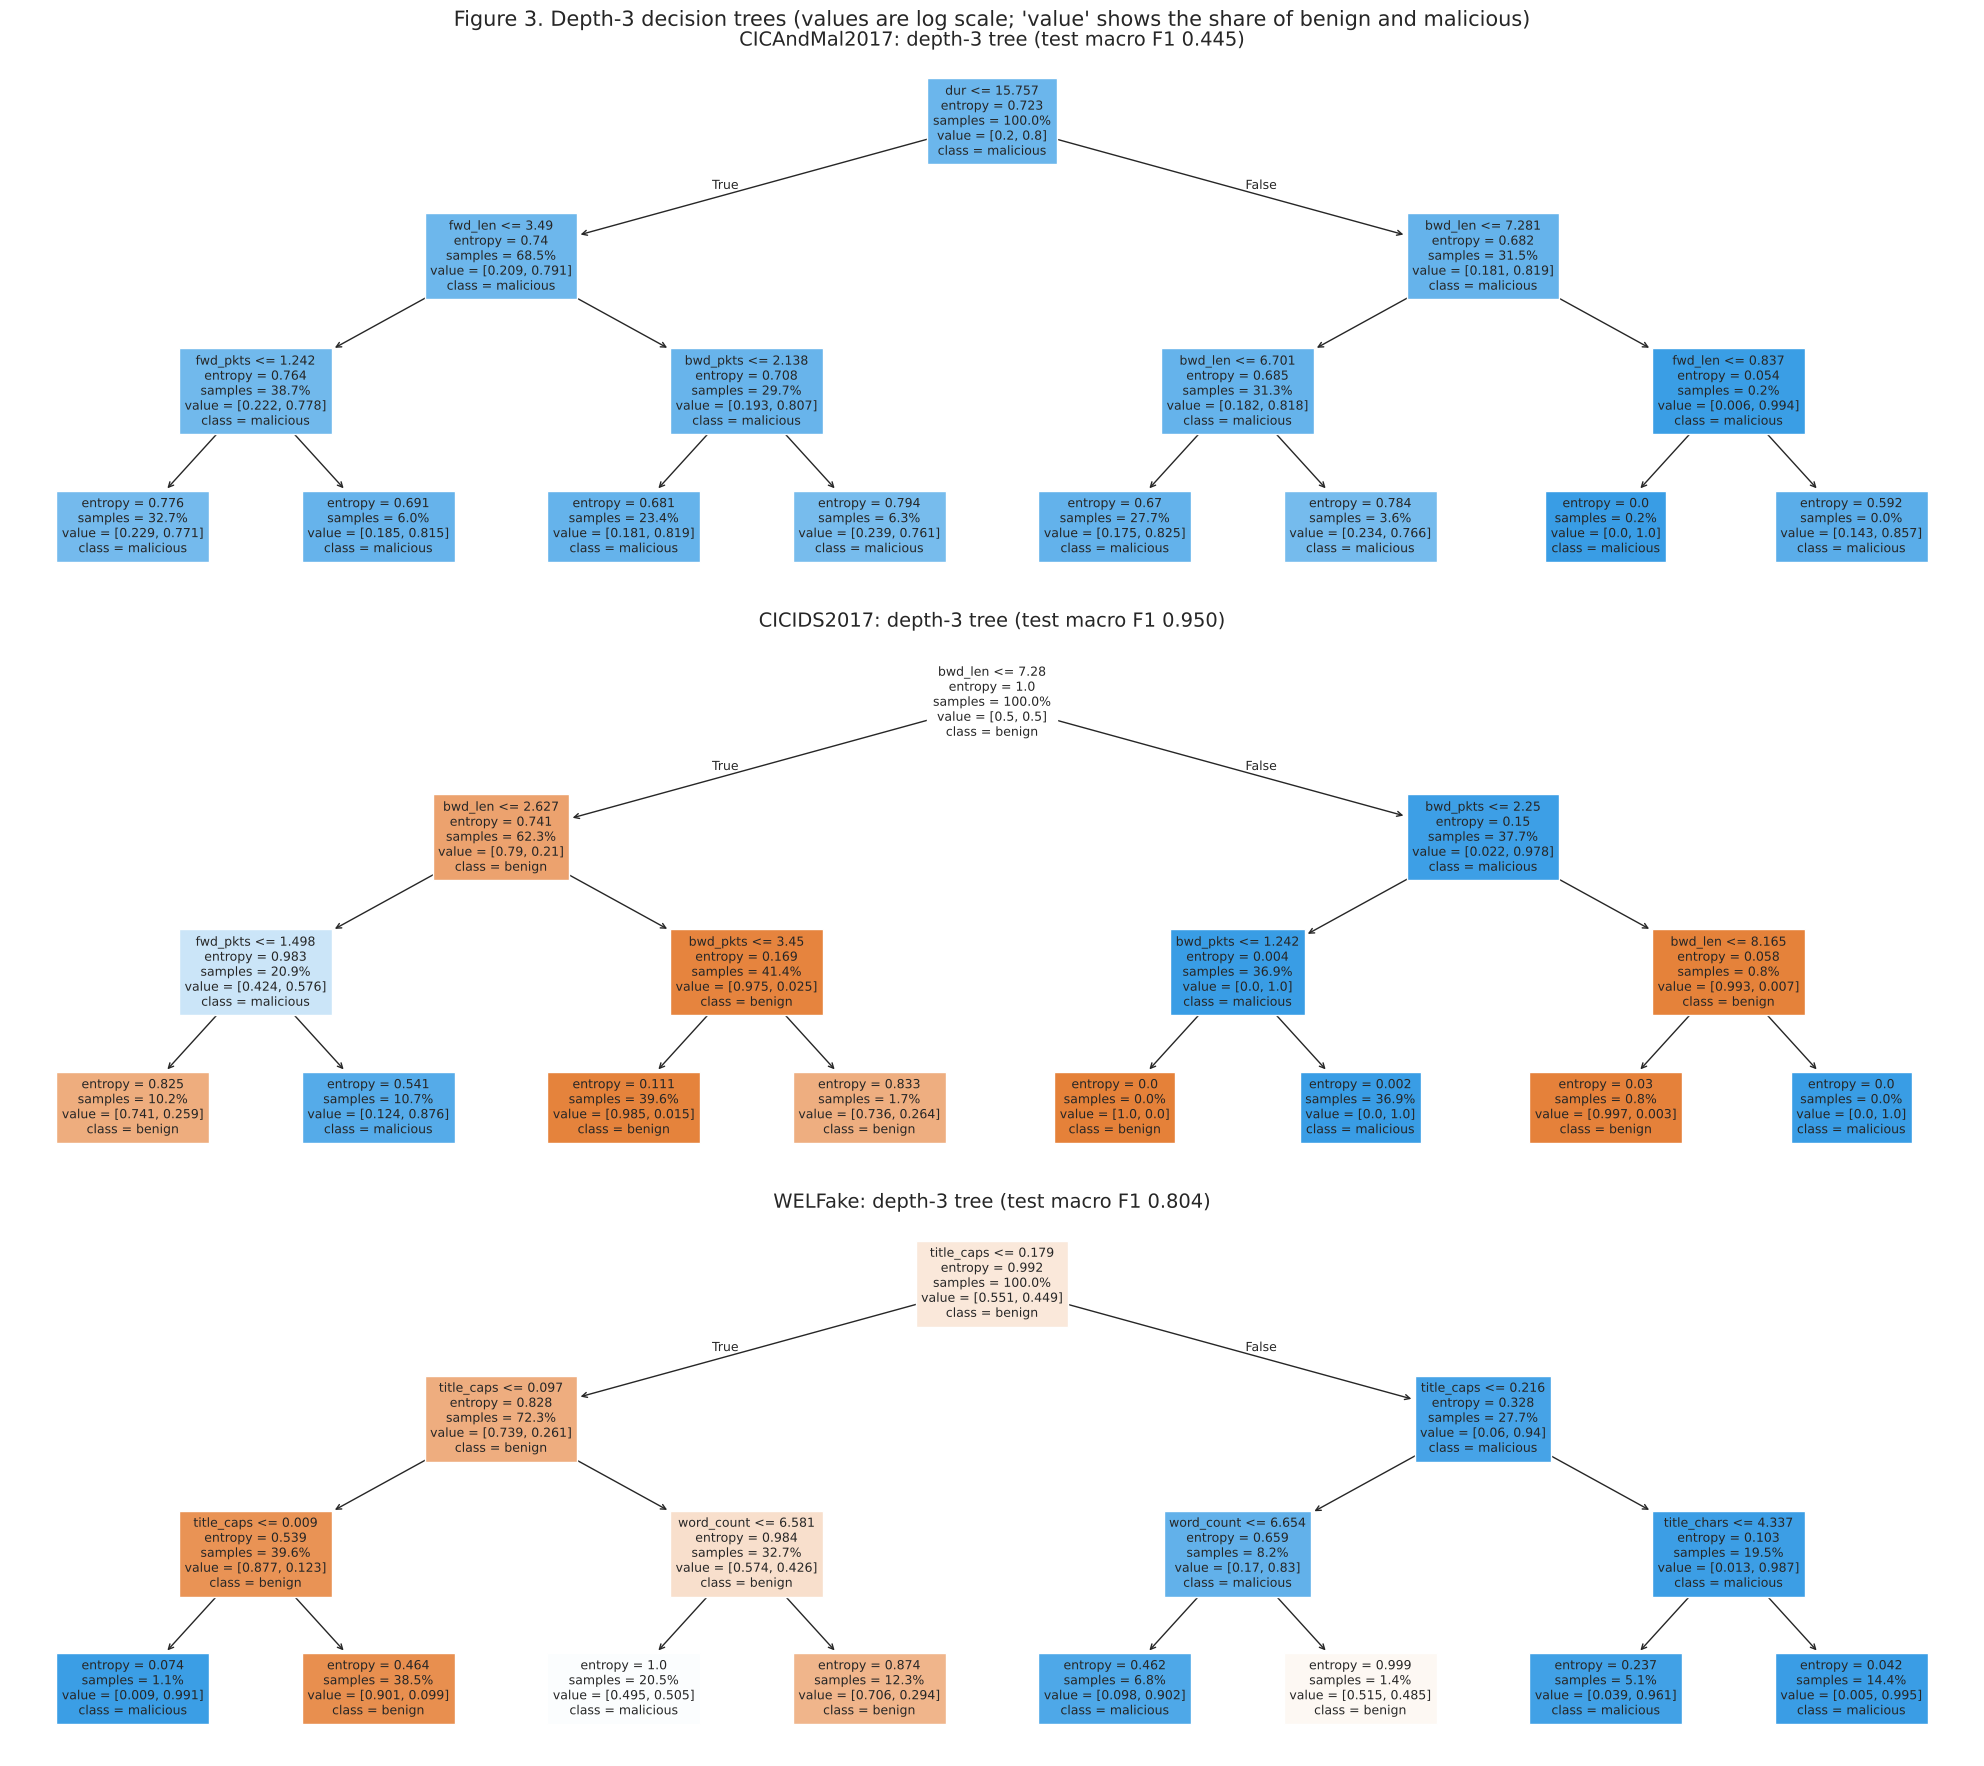

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(20, 18))
for ax, (name, (Xtr, Xte, ytr, yte)) in zip(axes, SPLITS.items()):
    small_tree = DecisionTreeClassifier(max_depth=3, criterion="entropy", random_state=SEED).fit(Xtr, ytr)
    plot_tree(small_tree, feature_names=list(Xtr.columns), class_names=["benign", "malicious"], filled=True,
              impurity=True, proportion=True, ax=ax, fontsize=9)
    acc = f1_score(yte, small_tree.predict(Xte), average="macro")
    ax.set_title(f"{name}: depth-3 tree (test macro F1 {acc:.3f})", fontsize=14)
fig.suptitle("Figure 3. Depth-3 decision trees (values are log scale; 'value' shows the share of benign and malicious)", fontsize=15)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_small_trees.png", dpi=120); plt.show()

Figure 3 shows what each domain relies on first:
- CICIDS2017 starts with backward packet length, then forward packet counts and lengths. Three splits already give macro F1 around 0.95. A typical attack flow has tiny or empty backward packets: the server barely answers a flood.
- WELFake starts with the share of capital letters in the title. Titles with many capitals are mostly fake.
- CICAndMal2017's small tree predicts malware in every leaf. No split separates the classes well enough to change the majority.

So even the very first decision is different in each domain, and only CICIDS2017 and WELFake have a clear rule at all.

## 8. Random forests
### 8a. How the forest combines its trees
The lesson says a classification forest takes the most common class among its trees. sklearn actually averages each tree's class probabilities, which nearly always gives the same answer as a majority vote. Checking both:

In [16]:
Xtr, Xte, ytr, yte = SPLITS["WELFake"]
rf_small = RandomForestClassifier(n_estimators=25, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
tree_votes = np.array([t.predict(Xte.values) for t in rf_small.estimators_])
majority = (tree_votes.mean(axis=0) > 0.5).astype(int)
average = np.mean([t.predict_proba(Xte.values)[:, 1] for t in rf_small.estimators_], axis=0)
print("forest probability = average of the trees' probabilities:", np.allclose(average, rf_small.predict_proba(Xte)[:, 1]))
print(f"majority vote agrees with the forest's prediction for {np.mean(majority == rf_small.predict(Xte)):.1%} of articles")
print(f"single trees: test accuracy from {min(accuracy_score(yte, v) for v in tree_votes):.3f} to {max(accuracy_score(yte, v) for v in tree_votes):.3f}; forest: {accuracy_score(yte, rf_small.predict(Xte)):.3f}")

forest probability = average of the trees' probabilities: True
majority vote agrees with the forest's prediction for 100.0% of articles
single trees: test accuracy from 0.817 to 0.832; forest: 0.876


### 8b. Bagging and feature randomization, one at a time
Four models, each with 100 trees where relevant and no depth limit:
- one decision tree
- bagging only: each tree sees a different bootstrap sample of the rows, but every split can use every feature
- random forest: bootstrap samples plus a random subset of features at each split (max_features = "sqrt")
- random forest with max_features = 1: each split gets only one random feature (the most random)

In [17]:
MODELS = {"One decision tree": DecisionTreeClassifier(criterion="entropy", random_state=SEED),
          "Bagging only (all features at each split)": RandomForestClassifier(n_estimators=100, max_features=None, criterion="entropy", random_state=SEED, n_jobs=-1),
          "Random forest (sqrt features at each split)": RandomForestClassifier(n_estimators=100, max_features="sqrt", criterion="entropy", random_state=SEED, n_jobs=-1),
          "Random forest (1 feature at each split)": RandomForestClassifier(n_estimators=100, max_features=1, criterion="entropy", random_state=SEED, n_jobs=-1)}
compare = []
for name, (Xtr, Xte, ytr, yte) in SPLITS.items():
    idx = np.random.RandomState(SEED).choice(len(Xtr), min(50000, len(Xtr)), replace=False)
    for label, model in MODELS.items():
        model.fit(Xtr.iloc[idx], ytr[idx])
        p = model.predict_proba(Xte)[:, 1]
        compare.append({"dataset": name, "model": label, "train macro F1": f1_score(ytr[idx], model.predict(Xtr.iloc[idx]), average="macro"),
                        "test macro F1": f1_score(yte, p > 0.5, average="macro"), "test ROC AUC": roc_auc_score(yte, p)})
compare = pd.DataFrame(compare)
compare.pivot(index="model", columns="dataset", values=["test macro F1", "test ROC AUC"]).round(3)

test macro F1                     \
dataset                                     CICAndMal2017 CICIDS2017 WELFake   
model                                                                          
Bagging only (all features at each split)           0.521      0.990   0.875   
One decision tree                                   0.523      0.989   0.829   
Random forest (1 feature at each split)             0.520      0.990   0.878   
Random forest (sqrt features at each split)         0.520      0.991   0.877   

                                             test ROC AUC                     
dataset                                     CICAndMal2017 CICIDS2017 WELFake  
model                                                                         
Bagging only (all features at each split)           0.553      0.998   0.946  
One decision tree                                   0.525      0.990   0.830  
Random forest (1 feature at each split)             0.551      0.999   0.949  
Random forest (sqrt features at each split)         0.552      0.999   0.948

In [18]:
compare.pivot(index="model", columns="dataset", values="train macro F1").round(3)

dataset,CICAndMal2017,CICIDS2017,WELFake
model,,,
Bagging only (all features at each split),0.985,1.000,1.000
One decision tree,0.985,1.000,1.000
Random forest (1 feature at each split),0.985,1.000,1.000
Random forest (sqrt features at each split),0.985,1.000,1.000


Results:
- A single deep tree memorizes the training data perfectly (training macro F1 1.000 for CICIDS2017 and WELFake, 0.985 for CICAndMal2017), but on WELFake its test F1 is only 0.829.
- Bagging (each tree trained on a different bootstrap sample, then averaged) lifts WELFake from 0.829 to 0.875 and AUC from 0.830 to 0.946. Averaging many different overfit trees cancels out much of their individual noise.
- Adding feature randomization on top helps a little more (0.877 to 0.878) by making the trees less alike. The gain is small here because there are only 6 or 7 features, so the trees are already fairly different through bagging alone.
- Section 8a confirms how the trees are combined: the forest's probability is exactly the average of the trees' probabilities, and a majority vote gives the same prediction for 100% of articles. Single trees scored between 0.817 and 0.832 accuracy, while the forest scored 0.876.
- Figure 4: the out-of-bag accuracy levels off after about 50 to 100 trees, so 100 trees is enough.

### 8c. Number of trees and out-of-bag score
Each tree leaves out about a third of the rows from its bootstrap sample. The forest can score itself on those left-out rows (the out-of-bag or OOB score), which works like a free validation set.

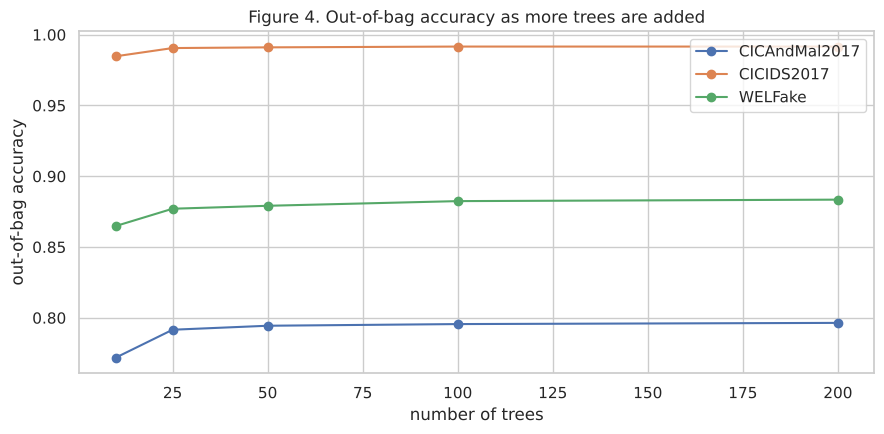

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, (Xtr, Xte, ytr, yte) in SPLITS.items():
    idx = np.random.RandomState(SEED).choice(len(Xtr), min(50000, len(Xtr)), replace=False)
    oob = []
    for n in [10, 25, 50, 100, 200]:
        rf = RandomForestClassifier(n_estimators=n, oob_score=True, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(Xtr.iloc[idx], ytr[idx])
        oob.append(rf.oob_score_)
    ax.plot([10, 25, 50, 100, 200], oob, "o-", label=name)
ax.set_xlabel("number of trees"); ax.set_ylabel("out-of-bag accuracy"); ax.legend()
ax.set_title("Figure 4. Out-of-bag accuracy as more trees are added")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_oob.png", dpi=150); plt.show()

### 8d. Tuned random forest
A small grid search over max_features and min_samples_leaf with 5-fold cross-validation on 50,000 rows (grouped by capture file for CICAndMal2017), then refit with 100 trees on the full training set. Leaves must hold at least 5 samples, which keeps the trees from memorizing single flows and keeps memory use reasonable.

In [20]:
RF = {}
for name, (Xtr, Xte, ytr, yte) in SPLITS.items():
    idx = np.random.RandomState(SEED).choice(len(Xtr), min(50000, len(Xtr)), replace=False)
    Xs, ys = Xtr.iloc[idx], ytr[idx]
    cv = GroupKFold(5).split(Xs, ys, DATA[name][0].loc[Xs.index, "file"]) if name == "CICAndMal2017" else 5
    search = GridSearchCV(RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1),
                          {"max_features": ["sqrt", 0.5], "min_samples_leaf": [5, 25, 100]}, cv=cv, scoring="f1_macro").fit(Xs, ys)
    rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1, **search.best_params_).fit(Xtr, ytr)
    RF[name] = rf
    p = rf.predict_proba(Xte)[:, 1]
    results.append({"dataset": name, "model": "Random forest (tuned)", "macro F1": f1_score(yte, p > 0.5, average="macro"), "ROC AUC": roc_auc_score(yte, p)})
    print(f"{name}: best settings {search.best_params_}, test macro F1 = {results[-1]['macro F1']:.3f}, AUC = {results[-1]['ROC AUC']:.3f}")

CICAndMal2017: best settings {'max_features': 0.5, 'min_samples_leaf': 5}, test macro F1 = 0.500, AUC = 0.600


CICIDS2017: best settings {'max_features': 0.5, 'min_samples_leaf': 5}, test macro F1 = 0.992, AUC = 1.000


WELFake: best settings {'max_features': 0.5, 'min_samples_leaf': 5}, test macro F1 = 0.880, AUC = 0.949


The tuned forests are the best models so far for CICIDS2017 (macro F1 0.992, AUC 1.000) and WELFake (macro F1 0.880, AUC 0.949). WELFake has improved every week, from AUC 0.896 with logistic regression to 0.937 with the Gaussian SVM and now 0.949. All three datasets picked half the features at each split and at least 5 samples per leaf.

CICAndMal2017 reaches its best AUC so far (0.600), but macro F1 is still 0.50. The forest ranks malware a little above benign, but not enough to separate them at any threshold.

## 9. Feature importances
Three ways to measure importance:
- split count: how often each feature is used for a split across all trees (the lesson's definition)
- impurity importance: how much each feature lowers the entropy or Gini in total (sklearn's feature_importances_)
- permutation importance: how much test macro F1 drops when that feature's values are shuffled (a check that works on the test set)

CICAndMal2017
          split count share  impurity importance  permutation importance
dur                   0.322                0.293                   0.044
iat                   0.321                0.286                   0.040
bytes_s               0.145                0.154                   0.037
fwd_len               0.079                0.100                   0.037
bwd_len               0.079                0.099                   0.033
fwd_pkts              0.027                0.035                   0.032
bwd_pkts              0.026                0.033                   0.025 



CICIDS2017
          split count share  impurity importance  permutation importance
bwd_len               0.058                0.421                   0.276
fwd_pkts              0.053                0.174                   0.050
bwd_pkts              0.048                0.116                   0.134
fwd_len               0.064                0.111                   0.089
iat                   0.323                0.080                   0.013
dur                   0.336                0.058                   0.005
bytes_s               0.118                0.040                   0.006 



WELFake
              split count share  impurity importance  permutation importance
title_caps                0.199                0.542                   0.254
title_chars               0.171                0.143                   0.063
word_count                0.263                0.115                   0.042
avg_word_len              0.250                0.071                   0.015
title_words               0.098                0.069                   0.068
exclaim                   0.019                0.060                   0.030 



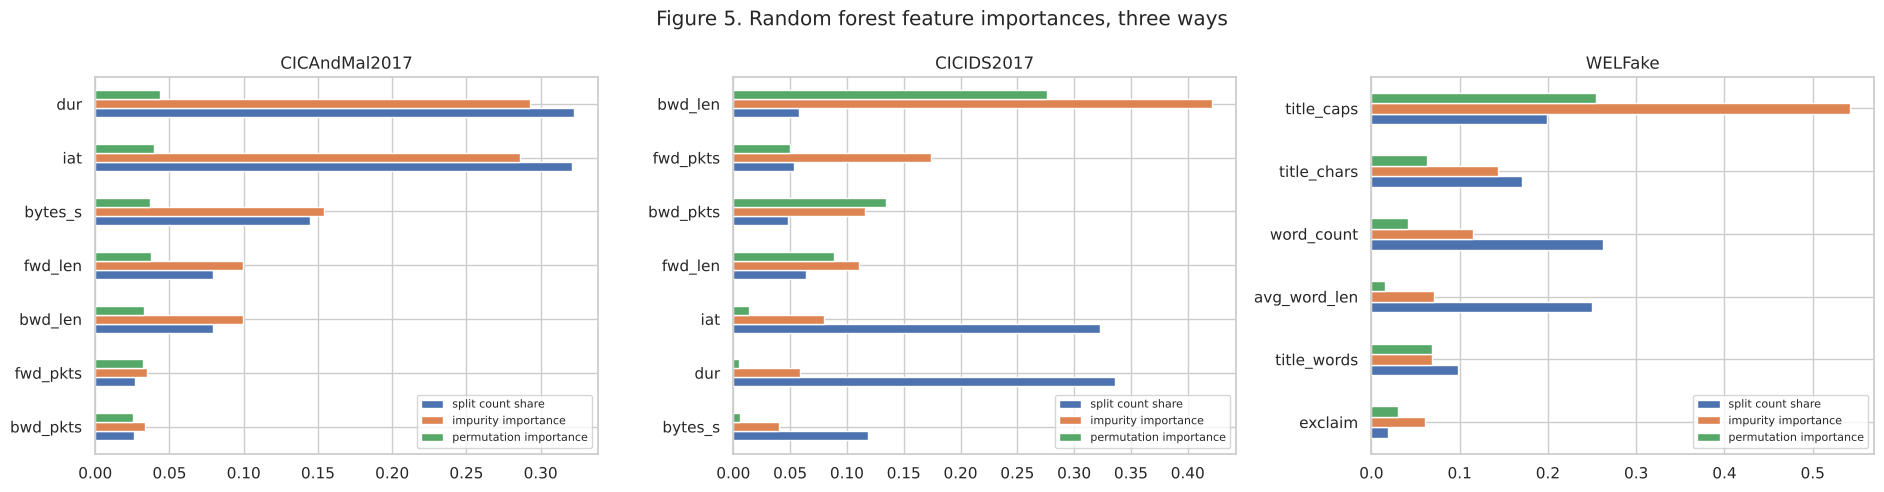

Rank correlation of impurity importances between the two network datasets: -0.75


In [21]:
IMP = {}
for name, (Xtr, Xte, ytr, yte) in SPLITS.items():
    rf = RF[name]
    counts = pd.Series(0, index=Xtr.columns)
    for t in rf.estimators_:
        used = t.tree_.feature[t.tree_.feature >= 0]
        counts += pd.Series(np.bincount(used, minlength=len(Xtr.columns)), index=Xtr.columns)
    idx = np.random.RandomState(SEED).choice(len(Xte), min(10000, len(Xte)), replace=False)
    perm = permutation_importance(rf, Xte.iloc[idx], yte[idx], scoring="f1_macro", n_repeats=3, random_state=SEED)
    IMP[name] = pd.DataFrame({"split count share": counts / counts.sum(),
                              "impurity importance": rf.feature_importances_,
                              "permutation importance": perm.importances_mean}, index=Xtr.columns)
    print(name); print(IMP[name].sort_values("impurity importance", ascending=False).round(3), "\n")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, name in zip(axes, SPLITS):
    IMP[name].sort_values("impurity importance").plot.barh(ax=ax)
    ax.set_title(name); ax.legend(fontsize=8)
fig.suptitle("Figure 5. Random forest feature importances, three ways")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_importances.png", dpi=150); plt.show()

net = pd.DataFrame({n: IMP[n]["impurity importance"] for n in ["CICAndMal2017", "CICIDS2017"]})
print("Rank correlation of impurity importances between the two network datasets:", round(net.corr(method="spearman").iloc[0, 1], 3))

Results:
- The three importance measures do not always agree. The lesson's definition (split count) is biased toward features with many different values: duration and inter-arrival time account for about a third of all splits in both network datasets, but in CICIDS2017 their permutation importance is close to zero. They get used often for small, unhelpful splits. Impurity and permutation importance are more trustworthy.
- CICIDS2017: backward packet length dominates (impurity 0.42, permutation 0.28), then backward and forward packet counts. This matches the first split of the small tree.
- WELFake: the share of capitals in the title dominates (0.54 and 0.25).
- CICAndMal2017: every feature has a permutation importance of only 0.03 to 0.04, because there is little real signal to lose.
- The rank correlation between the two network datasets' importances is -0.75. The features that matter most in CICIDS2017 (packet lengths and counts) matter least in CICAndMal2017, and the reverse. This is the clearest evidence so far against a universal fingerprint: even with the same features and the same model, the two network domains rely on nearly opposite features.

For Module C, SHAP values will be a better tool than any of these, because they explain each prediction and are not biased toward features with many values.

## 10. Do trees memorize CICAndMal2017 capture files?
Weeks 4 and 5 found no difference between a random split and a split by capture file, because the models learned almost nothing. A random forest with no limits on the trees (50 trees, leaves can hold a single flow) can memorize much more. Here I compare the two splits for the same forest.

In [22]:
df = mal
rows = []
for label in ["random split", "split by capture file"]:
    if label == "random split":
        tr, te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=df["malicious"])
    else:
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(df, groups=df["file"]))
    rf = RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1).fit(df.iloc[tr][NET], df.iloc[tr]["malicious"])
    p = rf.predict_proba(df.iloc[te][NET])[:, 1]
    del rf
    rows.append({"split": label, "macro F1": f1_score(df.iloc[te]["malicious"], p > 0.5, average="macro"), "ROC AUC": roc_auc_score(df.iloc[te]["malicious"], p)})
pd.DataFrame(rows)

,split,macro F1,ROC AUC
0,random split,0.543,0.592
1,split by capture file,0.536,0.573


With a forest that can memorize single flows, the random split scores higher than the split by capture file (AUC 0.592 vs 0.573). The gap is small but in the expected direction. The forest learns a little about specific captures, which looks like skill on a random split but does not carry over to new apps. The split by capture file is the honest number, and it is what this notebook uses for CICAndMal2017.

## 11. CICAndMal2017 with all flow features
So far every model used the same 7 flow features, and none could separate malware flows from benign ones. CICFlowMeter records about 80 features per flow (flags, packet size statistics, inter-arrival time statistics, window sizes, bulk and idle statistics). Here I reload CICAndMal2017 with every numeric feature except the identifiers (flow ID, IP addresses, ports, timestamp), and train a random forest with the split by capture file. To keep memory low, I keep a random 10% of each capture file while reading.

In [23]:
del RF, MODELS, rf_small                # free memory before loading the full feature set
import gc; gc.collect()
DROP = {"Flow ID", "Source IP", "Source Port", "Destination IP", "Destination Port", "Timestamp", "Label"}

def read_zip_all(zip_name, frac=0.10):
    frames = []
    with zipfile.ZipFile(DATA_DIR / zip_name) as z:
        for name in z.namelist():
            if name.endswith(".csv"):
                df = pd.read_csv(z.open(name), skipinitialspace=True, encoding="latin1", low_memory=False)
                df.columns = df.columns.str.strip()
                df = df.sample(frac=frac, random_state=SEED)
                df["file"] = name
                frames.append(df.drop(columns=[c for c in DROP if c in df.columns]))
    return pd.concat(frames, ignore_index=True)

parts = []
for cat in ["Benign", "Adware", "Ransomware", "Scareware", "SMSmalware"]:
    d = read_zip_all(f"{cat}-CSVs.zip"); d["category"] = cat; parts.append(d)
full = pd.concat(parts, ignore_index=True); del parts
FULL_FEATS = [c for c in full.columns if c not in ("file", "category")]
full[FULL_FEATS] = full[FULL_FEATS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
full = full.dropna().drop_duplicates()
FULL_FEATS = [c for c in FULL_FEATS if full[c].nunique() > 1]          # drop columns that never change
full["malicious"] = (full["category"] != "Benign").astype(int)
full_all = full.copy()                     # kept for the per-capture view in section 11b
full = pd.concat([g.sample(min(len(g), 25000), random_state=SEED) for _, g in full.groupby("category")], ignore_index=True)
print(f"{len(full)} flows, {len(FULL_FEATS)} usable features, malicious share = {full['malicious'].mean():.2f}")

123692 flows, 66 usable features, malicious share = 0.80


,features,macro F1,ROC AUC
0,7 features (as before),0.482,0.582
1,all 66 features,0.496,0.624


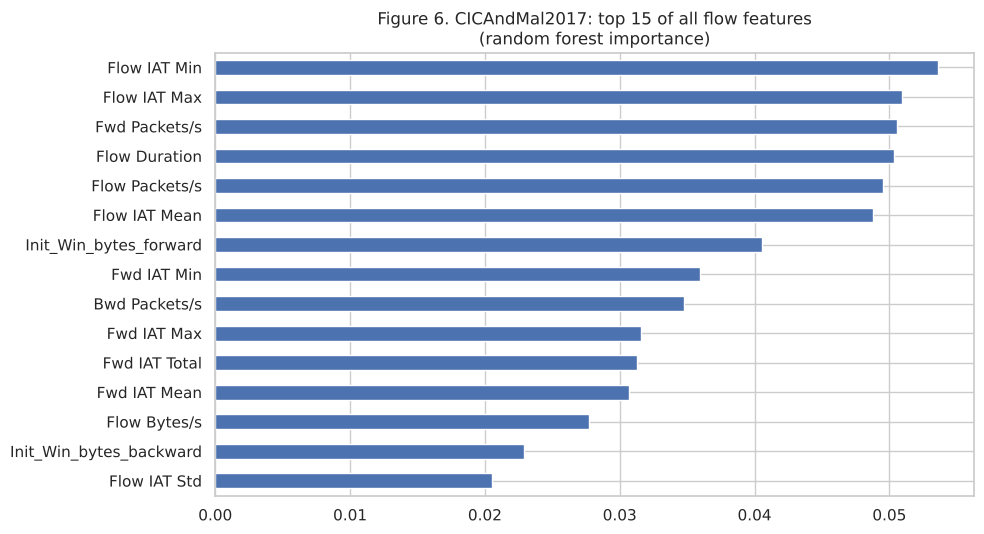

In [24]:
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(full, groups=full["file"]))
FULL_ROWS = []
for label, feats in [("7 features (as before)", ["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Fwd Packet Length Mean", "Bwd Packet Length Mean", "Flow IAT Mean", "Flow Bytes/s"]),
                     (f"all {len(FULL_FEATS)} features", FULL_FEATS)]:
    rf_full = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(full.iloc[tr][feats], full.iloc[tr]["malicious"])
    p = rf_full.predict_proba(full.iloc[te][feats])[:, 1]
    FULL_ROWS.append({"features": label, "macro F1": f1_score(full.iloc[te]["malicious"], p > 0.5, average="macro"), "ROC AUC": roc_auc_score(full.iloc[te]["malicious"], p)})
display(pd.DataFrame(FULL_ROWS))

top = pd.Series(rf_full.feature_importances_, index=FULL_FEATS).sort_values(ascending=False).head(15)
top.sort_values().plot.barh(figsize=(10, 5.5), title="Figure 6. CICAndMal2017: top 15 of all flow features\n(random forest importance)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_full_features.png", dpi=150); plt.show()

Using all the usable flow features (66 after removing identifiers and columns that never change) helps only a little: AUC goes from 0.582 to 0.624 and macro F1 from 0.48 to 0.50. The most important features (Figure 6) are mostly timing and window-size features, not packet size. So the problem is not just that the first six weeks used too few features. Single malware flows really do look like normal app flows.

### 11b. Classifying whole captures instead of single flows
Each CICAndMal2017 capture file is one app running on one phone. Instead of judging each flow alone, I describe each capture by the average and standard deviation of every flow feature across its flows, plus its number of flows, and classify the capture as malware or benign. Each capture is now one independent sample, so ordinary stratified 5-fold cross-validation is fine.

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
agg = full_all.groupby("file")[FULL_FEATS].agg(["mean", "std"]).fillna(0)
agg.columns = [f"{a} ({b})" for a, b in agg.columns]
agg["flows in capture"] = full_all.groupby("file").size()
y_cap = full_all.groupby("file")["malicious"].first().loc[agg.index].values
agg = agg[agg["flows in capture"] >= 5]                     # captures with too few sampled flows are dropped
y_cap = full_all.groupby("file")["malicious"].first().loc[agg.index].values
print(f"{len(agg)} captures ({y_cap.sum()} malware, {(1 - y_cap).sum()} benign), {agg.shape[1]} features")

rf_cap = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1)
p_cap = cross_val_predict(rf_cap, agg, y_cap, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
cap_result = {"macro F1": f1_score(y_cap, p_cap > 0.5, average="macro"), "ROC AUC": roc_auc_score(y_cap, p_cap)}
results.append({"dataset": "CICAndMal2017", "model": "Random forest, per capture (all features)", **cap_result})
print(f"per-capture random forest (5-fold CV): macro F1 = {cap_result['macro F1']:.3f}, ROC AUC = {cap_result['ROC AUC']:.3f}")

# check: is the result only driven by how long each capture is?
agg_no_len = agg.drop(columns=["flows in capture"])
p_cap2 = cross_val_predict(rf_cap, agg_no_len, y_cap, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"same model without the number of flows: macro F1 = {f1_score(y_cap, p_cap2 > 0.5, average='macro'):.3f}, ROC AUC = {roc_auc_score(y_cap, p_cap2):.3f}")
p_len = cross_val_predict(rf_cap, agg[["flows in capture"]], y_cap, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"number of flows alone: macro F1 = {f1_score(y_cap, p_len > 0.5, average='macro'):.3f}, ROC AUC = {roc_auc_score(y_cap, p_len):.3f}")

top_cap = pd.Series(rf_cap.fit(agg, y_cap).feature_importances_, index=agg.columns).sort_values(ascending=False).head(10)
print("\nmost important capture-level features:"); print(top_cap.round(3).to_string())

2126 captures (426 malware, 1700 benign), 133 features


per-capture random forest (5-fold CV): macro F1 = 0.967, ROC AUC = 0.989


same model without the number of flows: macro F1 = 0.933, ROC AUC = 0.982


number of flows alone: macro F1 = 0.905, ROC AUC = 0.944



most important capture-level features:
flows in capture              0.214
Active Std (std)              0.052
ACK Flag Count (std)          0.052
Active Std (mean)             0.040
Down/Up Ratio (mean)          0.030
Min Packet Length (std)       0.025
FIN Flag Count (mean)         0.022
Active Min (std)              0.022
Fwd Packet Length Min (std)   0.019
Active Max (std)              0.019


This is the most important result for Module C so far. Judged one flow at a time, CICAndMal2017 malware is almost impossible to detect (AUC about 0.6). Judged one capture at a time, the random forest reaches macro F1 0.967 and AUC 0.989, well above the proposal target of 0.85.

But there is a warning. The number of flows in a capture is the top feature, and on its own it already gets AUC 0.944. That probably reflects how the data was collected (malware and benign apps were captured in different sessions and for different lengths), not how malware behaves. Without that feature the model still gets macro F1 0.933 and AUC 0.982, using things like how much flag counts and active times vary across the capture's flows. Some of those may also be collection differences.

For Module C this means:
- Classify CICAndMal2017 at the capture (app) level instead of the flow level.
- Check that the result is not just collection differences, for example by leaving out length-related features or comparing captures of similar length.
- In the SHAP comparison, be careful that the explanations for CICAndMal2017 might partly describe how the dataset was recorded.

## 12. Summary

macro F1                     \
dataset                                   CICAndMal2017 CICIDS2017 WELFake   
model                                                                        
Decision tree (tuned)                             0.537      0.992   0.868   
Random forest (tuned)                             0.500      0.992   0.880   
Random forest, per capture (all features)         0.967        NaN     NaN   

                                                ROC AUC                     
dataset                                   CICAndMal2017 CICIDS2017 WELFake  
model                                                                       
Decision tree (tuned)                             0.539      0.998   0.936  
Random forest (tuned)                             0.600      1.000   0.949  
Random forest, per capture (all features)         0.989        NaN     NaN

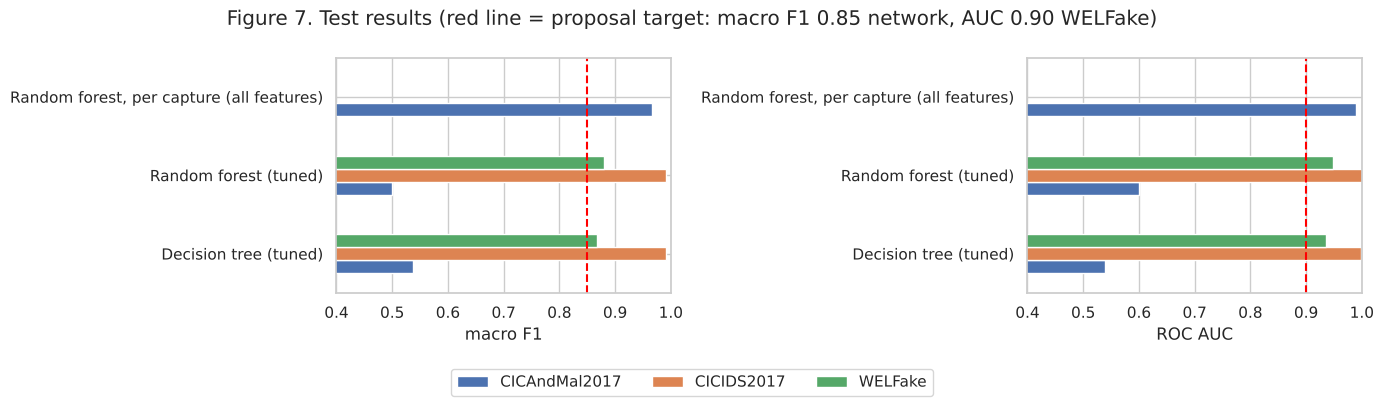

In [26]:
summary = pd.DataFrame(results)
display(summary.pivot(index="model", columns="dataset", values=["macro F1", "ROC AUC"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric, target in [(axes[0], "macro F1", 0.85), (axes[1], "ROC AUC", 0.90)]:
    summary.pivot(index="model", columns="dataset", values=metric).plot.barh(ax=ax, legend=False)
    ax.axvline(target, color="red", ls="--"); ax.set_xlim(0.4, 1); ax.set_xlabel(metric); ax.set_ylabel("")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
fig.suptitle("Figure 7. Test results (red line = proposal target: macro F1 0.85 network, AUC 0.90 WELFake)")
plt.tight_layout(rect=[0, 0.1, 1, 1]); plt.savefig(FIG_DIR / "fig7_summary.png", dpi=150); plt.show()

Week 6 conclusions:
1. Trees overfit exactly as the lesson describes. Deep trees reach near-perfect training scores, and WELFake validation peaks around depth 12. Max depth, min samples per leaf and min samples per split all control this.
2. Random forests fix much of the overfitting by averaging many different trees. On WELFake, bagging alone raised test macro F1 from 0.829 (one tree) to 0.875, and AUC from 0.830 to 0.946.
3. The tuned random forests are the best flow- and article-level models so far: CICIDS2017 macro F1 0.992 and AUC 1.000, WELFake macro F1 0.880 and AUC 0.949. Both are above the proposal targets.
4. Feature importances differ sharply between domains. The two network datasets' importance rankings have a correlation of -0.75, the clearest evidence so far that malicious signatures are domain-specific.
5. CICAndMal2017 cannot be solved one flow at a time, even with all 66 flow features (AUC 0.62). Classifying whole captures works (AUC 0.989), but part of that signal may come from how the data was collected and must be checked in Module C.
6. Random forests are a good choice for the SHAP stage of the capstone. They are accurate, need no scaling, and SHAP has a fast exact method for trees.

## 13. Think About It

Decision trees:

1. Why is there a minus sign in entropy? Probabilities are between 0 and 1, so ln(p) is always 0 or negative. The minus sign makes entropy positive, so more uncertainty gives a bigger number. For a 50/50 node, -0.5 ln(0.5) - 0.5 ln(0.5) = 0.693.

2. With 1,024 samples and one sample per leaf, how many nodes does the tree need? There are 1,024 leaves. Each split creates one extra leaf, so there are 1,023 decision nodes, for 2,047 nodes in total.

3. How many decisions from the root to a single leaf? If every split cuts the samples in half, 1,024 becomes 512, 256, ... 1 after log2(1024) = 10 decisions. That is the shortest possible. A lopsided tree could need many more. The CICAndMal2017 tree in section 6 grew to depth 30 and 47,946 leaves when allowed to, which shows how far an unlimited tree goes on real data.

Random forests:

4. Why does a random forest randomize features? If every split could use every feature, most trees would pick the same strong feature first and end up very similar. Averaging similar trees does not cancel their mistakes. Forcing each split to choose from a random subset makes the trees different. In section 8b, adding feature randomization on top of bagging improved WELFake slightly (0.875 to 0.878). The gain is small because there are only 6 features.

5. Why does a random forest combine the judgments of many trees? Each deep tree overfits in its own way, but their mistakes are partly random, so averaging cancels much of the noise while keeping the real pattern. On WELFake the single trees scored 0.817 to 0.832 accuracy and the forest of 25 trees scored 0.876.

## 14. Notes for the Milestone One write-up
| Rubric item | What I did |
|---|---|
| Avoiding overfitting | Max depth, min samples per leaf and min samples per split for trees; bagging, feature randomization and out-of-bag scores for forests; 80/20 train/test split; split by capture file for CICAndMal2017 |
| Metrics | Macro F1 and ROC AUC on the test set, out-of-bag accuracy, three kinds of feature importance |
| Hyperparameter tuning | Grid search with 5-fold cross-validation over max depth, min samples per leaf and per split (trees), and max features and min samples per leaf (forests) |
| How EDA helped | Earlier weeks showed packet size and timing features matter most, and that CICAndMal2017 flows are not independent, which led to the split by capture file, the test with all flow features and the per-capture view |